In [5]:
from google.colab import files
uploaded = files.upload()

Saving Ice_cream selling data.csv to Ice_cream selling data (1).csv


Training finished successfully! Final Loss: 0.03394


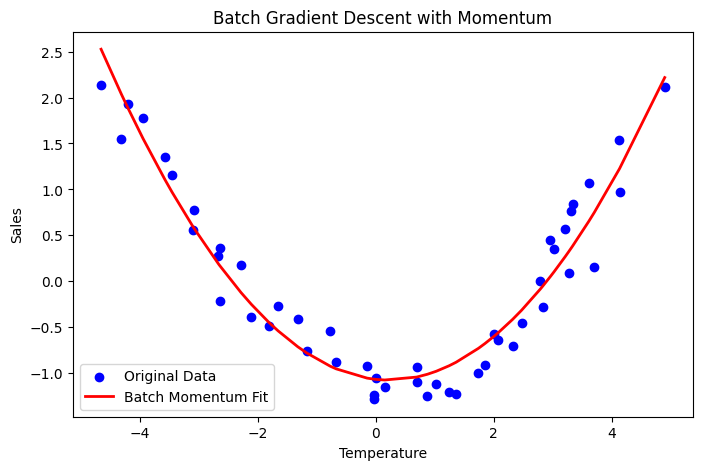

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures

data = pd.read_csv('Ice_cream selling data.csv')
X_input = data[['Temperature (°C)']].values
y_target = data['Ice Cream Sales (units)'].values

poly_feat = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_feat.fit_transform(X_input)

X_mean = np.mean(X_poly, axis=0)
X_std = np.std(X_poly, axis=0)
X_poly = (X_poly - X_mean) / X_std

y_mean = np.mean(y_target)
y_std = np.std(y_target)
y_scaled = (y_target - y_mean) / y_std

np.random.seed(42)
weights = np.zeros(X_poly.shape[1])
bias = 0.0

learning_rate = 0.05
momentum_rate = 0.9
n_epochs = 1000
m_samples = len(y_scaled)

v_weights = np.zeros_like(weights)
v_bias = 0.0

for epoch in range(n_epochs):
    y_predicted = np.dot(X_poly, weights) + bias
    err = y_predicted - y_scaled

    grad_w = (1 / m_samples) * np.dot(X_poly.T, err)
    grad_b = (1 / m_samples) * np.sum(err)

    v_weights = momentum_rate * v_weights + learning_rate * grad_w
    v_bias = momentum_rate * v_bias + learning_rate * grad_b

    weights = weights - v_weights
    bias = bias - v_bias

final_loss = (1 / (2 * m_samples)) * np.sum(err ** 2)
print(f"Training finished successfully! Final Loss: {final_loss:.5f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_input, y_scaled, color='blue', label='Original Data')
y_final_pred = np.dot(X_poly, weights) + bias
sorted_indices = np.argsort(X_input.flatten())
plt.plot(X_input[sorted_indices], y_final_pred[sorted_indices], color='red', linewidth=2, label='Batch Momentum Fit')
plt.xlabel('Temperature')
plt.ylabel('Sales')
plt.title('Batch Gradient Descent with Momentum')
plt.legend()
plt.show()